#### **Loading libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import joblib
import json
from pathlib import Path

#### **Loading Data**

In [2]:
files = [
    "Streaming_History_Audio_2026_01.json",
    "Streaming_History_Audio_2026_02.json",
    "Streaming_History_Audio_2026_03.json",
]

In [3]:
df = pd.concat((pd.read_json(f) for f in files), ignore_index=True)
df["ts"] = pd.to_datetime(df["ts"])

In [4]:
df.head(4)

,ts,platform,ms_played,conn_country,ip_addr,master_metadata_track_name,master_metadata_album_artist_name,master_metadata_album_album_name,spotify_track_uri,episode_name,...,audiobook_uri,audiobook_chapter_uri,audiobook_chapter_title,reason_start,reason_end,shuffle,skipped,offline,offline_timestamp,incognito_mode
0,2025-12-31 22:49:42+00:00,windows,5689,KE,154.159.237.154,Feels Like Summer,Childish Gambino,Summer Pack,spotify:track:7p4vHnYXkxlzvfePJVpcTr,NaN,...,NaN,NaN,NaN,trackdone,logout,True,False,False,1767221375,False
1,2025-12-31 22:49:42+00:00,windows,227068,KE,154.159.237.154,All I Need,Radiohead,In Rainbows,spotify:track:5Qv2Nby1xTr9pQyjkrc94J,NaN,...,NaN,NaN,NaN,fwdbtn,trackdone,True,False,False,1767221155,False
2,2026-01-01 07:29:39+00:00,android,228606,KE,154.159.237.154,I Sat by the Ocean,Queens of the Stone Age,...Like Clockwork,spotify:track:1D3YGmST01Ba0WRiT7THPG,NaN,...,NaN,NaN,NaN,trackdone,trackdone,False,False,False,1767252352,False
3,2026-01-01 07:40:09+00:00,android,381343,KE,154.159.237.154,the BLACK seminole.,Lil Yachty,Let’s Start Here.,spotify:track:1rydhdFtKe2CRkiaVb7aGF,NaN,...,NaN,NaN,NaN,trackdone,trackdone,False,False,False,1767252578,False


In [5]:
df.tail(5)

,ts,platform,ms_played,conn_country,ip_addr,master_metadata_track_name,master_metadata_album_artist_name,master_metadata_album_album_name,spotify_track_uri,episode_name,...,audiobook_uri,audiobook_chapter_uri,audiobook_chapter_title,reason_start,reason_end,shuffle,skipped,offline,offline_timestamp,incognito_mode
44144,2026-10-09 19:04:15+00:00,windows,353438,KE,154.159.237.166,Send It On,D'Angelo,Voodoo,spotify:track:5LIwaG8Wl9LfExcmiRQm7J,NaN,...,NaN,NaN,NaN,trackdone,trackdone,False,False,False,1791572301,0.0
44145,2026-10-09 19:08:51+00:00,windows,276251,KE,154.159.237.166,Rose Rouge,Jorja Smith,Rose Rouge,spotify:track:6XM6FI6rPJBnhoF6heNHeN,NaN,...,NaN,NaN,NaN,trackdone,trackdone,False,False,False,1791572654,0.0
44146,2026-10-09 19:14:22+00:00,windows,333941,KE,154.159.237.166,Bag Lady,Erykah Badu,Mama's Gun,spotify:track:7BgUcOjSOlKJXASLgJ6bx1,NaN,...,NaN,NaN,NaN,trackdone,trackdone,False,False,False,1791572928,0.0
44147,2026-10-09 19:16:34+00:00,windows,135047,KE,154.159.237.166,A Fan's Mail (Tron Song Suite II),Thundercat,Drunk,spotify:track:6qXNCWY49AaZ5nfp9AJIc5,NaN,...,NaN,NaN,NaN,trackdone,trackdone,False,False,False,1791573259,0.0
44148,2026-10-09 19:23:33+00:00,windows,422791,KE,154.159.237.166,That Magic,India.Arie,Worthy,spotify:track:5vCy6QmR8OTHG47W4egqx0,NaN,...,NaN,NaN,NaN,trackdone,trackdone,False,False,False,1791573390,0.0


In [6]:
df.describe(include='all')


,ts,platform,ms_played,conn_country,ip_addr,master_metadata_track_name,master_metadata_album_artist_name,master_metadata_album_album_name,spotify_track_uri,episode_name,...,audiobook_uri,audiobook_chapter_uri,audiobook_chapter_title,reason_start,reason_end,shuffle,skipped,offline,offline_timestamp,incognito_mode
count,44149,44149,44149.000000,44149,44149,44142,44142,44142,44142,7,...,0.0,0.0,0.0,44149,44149,44149,44149,44149,4.414900e+04,44115
unique,NaN,6,NaN,2,348,7405,2211,4266,8061,6,...,NaN,NaN,NaN,10,11,2,2,2,NaN,2
top,NaN,windows,NaN,KE,154.159.237.141,"The Moon Cave (feat. Asha Puthli, Bobby Womack...",Tame Impala,The Fall-Off,spotify:track:6VflG4mpZSlpKnqNRL3NO9,"#120 'I went to Diani with a Wanted Criminal!""...",...,NaN,NaN,NaN,fwdbtn,fwdbtn,False,True,False,NaN,False
freq,NaN,33445,NaN,44139,1339,77,1411,455,77,2,...,NaN,NaN,NaN,27444,28162,28537,29632,42232,NaN,44093
mean,2026-05-19 22:46:29.129085+00:00,NaN,80835.824209,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.779230e+09,NaN
min,2025-12-31 22:49:42+00:00,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.767221e+09,NaN
25%,2026-03-02 21:23:05+00:00,NaN,1113.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.772487e+09,NaN
50%,2026-05-23 17:57:59+00:00,NaN,4740.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.779559e+09,NaN
75%,2026-08-04 17:31:46+00:00,NaN,188362.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.785864e+09,NaN
max,2026-10-09 19:23:33+00:00,NaN,762216.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.791573e+09,NaN


#### **Data Cleaning**

In [7]:
df.columns

Index(['ts', 'platform', 'ms_played', 'conn_country', 'ip_addr',
       'master_metadata_track_name', 'master_metadata_album_artist_name',
       'master_metadata_album_album_name', 'spotify_track_uri', 'episode_name',
       'episode_show_name', 'spotify_episode_uri', 'audiobook_title',
       'audiobook_uri', 'audiobook_chapter_uri', 'audiobook_chapter_title',
       'reason_start', 'reason_end', 'shuffle', 'skipped', 'offline',
       'offline_timestamp', 'incognito_mode'],
      dtype='str')

In [8]:
df_2 = df.drop(columns=["ip_addr", "conn_country", "offline_timestamp",
                      "episode_name", "episode_show_name", "spotify_episode_uri",
                      "audiobook_title", "audiobook_uri",
                      "audiobook_chapter_uri", "audiobook_chapter_title"],
             errors="ignore")

In [9]:
df["ts"] = pd.to_datetime(df["ts"])
df_2 = df.dropna(subset=["master_metadata_album_artist_name"])
df_2 = df.rename(columns={"master_metadata_album_artist_name": "artist"})

In [10]:
df_2["minutes"] = df["ms_played"] / 60_000

In [11]:
df_2["Device"] =df["platform"]



In [12]:
df_2["Track name"] =df["master_metadata_track_name"]


In [13]:
df_2.describe(include='all')

,ts,platform,ms_played,conn_country,ip_addr,master_metadata_track_name,artist,master_metadata_album_album_name,spotify_track_uri,episode_name,...,reason_start,reason_end,shuffle,skipped,offline,offline_timestamp,incognito_mode,minutes,Device,Track name
count,44149,44149,44149.000000,44149,44149,44142,44142,44142,44142,7,...,44149,44149,44149,44149,44149,4.414900e+04,44115,44149.000000,44149,44142
unique,NaN,6,NaN,2,348,7405,2211,4266,8061,6,...,10,11,2,2,2,NaN,2,NaN,6,7405
top,NaN,windows,NaN,KE,154.159.237.141,"The Moon Cave (feat. Asha Puthli, Bobby Womack...",Tame Impala,The Fall-Off,spotify:track:6VflG4mpZSlpKnqNRL3NO9,"#120 'I went to Diani with a Wanted Criminal!""...",...,fwdbtn,fwdbtn,False,True,False,NaN,False,NaN,windows,"The Moon Cave (feat. Asha Puthli, Bobby Womack..."
freq,NaN,33445,NaN,44139,1339,77,1411,455,77,2,...,27444,28162,28537,29632,42232,NaN,44093,NaN,33445,77
mean,2026-05-19 22:46:29.129085+00:00,NaN,80835.824209,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.779230e+09,NaN,1.347264,NaN,NaN
min,2025-12-31 22:49:42+00:00,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.767221e+09,NaN,0.000000,NaN,NaN
25%,2026-03-02 21:23:05+00:00,NaN,1113.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.772487e+09,NaN,0.018550,NaN,NaN
50%,2026-05-23 17:57:59+00:00,NaN,4740.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.779559e+09,NaN,0.079000,NaN,NaN
75%,2026-08-04 17:31:46+00:00,NaN,188362.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.785864e+09,NaN,3.139367,NaN,NaN
max,2026-10-09 19:23:33+00:00,NaN,762216.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.791573e+09,NaN,12.703600,NaN,NaN


In [14]:
columns_to_drop = ["master_metadata_track_name","master_metadata_album_artist_name",]

In [15]:
df_3 = df_2.drop(columns=columns_to_drop,errors = 'ignore')
print(f"Original columns: {df_2.shape[1]}")
print(f"Cleaned columns:  {df_3.shape[1]}")

Original columns: 26
Cleaned columns:  25


In [16]:
df_3

,ts,platform,ms_played,conn_country,ip_addr,artist,master_metadata_album_album_name,spotify_track_uri,episode_name,episode_show_name,...,reason_start,reason_end,shuffle,skipped,offline,offline_timestamp,incognito_mode,minutes,Device,Track name
0,2025-12-31 22:49:42+00:00,windows,5689,KE,154.159.237.154,Childish Gambino,Summer Pack,spotify:track:7p4vHnYXkxlzvfePJVpcTr,NaN,NaN,...,trackdone,logout,True,False,False,1767221375,False,0.094817,windows,Feels Like Summer
1,2025-12-31 22:49:42+00:00,windows,227068,KE,154.159.237.154,Radiohead,In Rainbows,spotify:track:5Qv2Nby1xTr9pQyjkrc94J,NaN,NaN,...,fwdbtn,trackdone,True,False,False,1767221155,False,3.784467,windows,All I Need
2,2026-01-01 07:29:39+00:00,android,228606,KE,154.159.237.154,Queens of the Stone Age,...Like Clockwork,spotify:track:1D3YGmST01Ba0WRiT7THPG,NaN,NaN,...,trackdone,trackdone,False,False,False,1767252352,False,3.810100,android,I Sat by the Ocean
3,2026-01-01 07:40:09+00:00,android,381343,KE,154.159.237.154,Lil Yachty,Let’s Start Here.,spotify:track:1rydhdFtKe2CRkiaVb7aGF,NaN,NaN,...,trackdone,trackdone,False,False,False,1767252578,False,6.355717,android,the BLACK seminole.
4,2026-01-01 07:40:32+00:00,android,23844,KE,154.159.237.154,Ms. Lauryn Hill,The Miseducation of Lauryn Hill,spotify:track:2RPhXg9D4JOkryUznL0aaB,NaN,NaN,...,trackdone,fwdbtn,False,True,False,1767253207,False,0.397400,android,Forgive Them Father
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44144,2026-10-09 19:04:15+00:00,windows,353438,KE,154.159.237.166,D'Angelo,Voodoo,spotify:track:5LIwaG8Wl9LfExcmiRQm7J,NaN,NaN,...,trackdone,trackdone,False,False,False,1791572301,0.0,5.890633,windows,Send It On
44145,2026-10-09 19:08:51+00:00,windows,276251,KE,154.159.237.166,Jorja Smith,Rose Rouge,spotify:track:6XM6FI6rPJBnhoF6heNHeN,NaN,NaN,...,trackdone,trackdone,False,False,False,1791572654,0.0,4.604183,windows,Rose Rouge
44146,2026-10-09 19:14:22+00:00,windows,333941,KE,154.159.237.166,Erykah Badu,Mama's Gun,spotify:track:7BgUcOjSOlKJXASLgJ6bx1,NaN,NaN,...,trackdone,trackdone,False,False,False,1791572928,0.0,5.565683,windows,Bag Lady
44147,2026-10-09 19:16:34+00:00,windows,135047,KE,154.159.237.166,Thundercat,Drunk,spotify:track:6qXNCWY49AaZ5nfp9AJIc5,NaN,NaN,...,trackdone,trackdone,False,False,False,1791573259,0.0,2.250783,windows,A Fan's Mail (Tron Song Suite II)


#### **Analysis**

In [17]:
df_3.head(2)

,ts,platform,ms_played,conn_country,ip_addr,artist,master_metadata_album_album_name,spotify_track_uri,episode_name,episode_show_name,...,reason_start,reason_end,shuffle,skipped,offline,offline_timestamp,incognito_mode,minutes,Device,Track name
0,2025-12-31 22:49:42+00:00,windows,5689,KE,154.159.237.154,Childish Gambino,Summer Pack,spotify:track:7p4vHnYXkxlzvfePJVpcTr,NaN,NaN,...,trackdone,logout,True,False,False,1767221375,False,0.094817,windows,Feels Like Summer
1,2025-12-31 22:49:42+00:00,windows,227068,KE,154.159.237.154,Radiohead,In Rainbows,spotify:track:5Qv2Nby1xTr9pQyjkrc94J,NaN,NaN,...,fwdbtn,trackdone,True,False,False,1767221155,False,3.784467,windows,All I Need


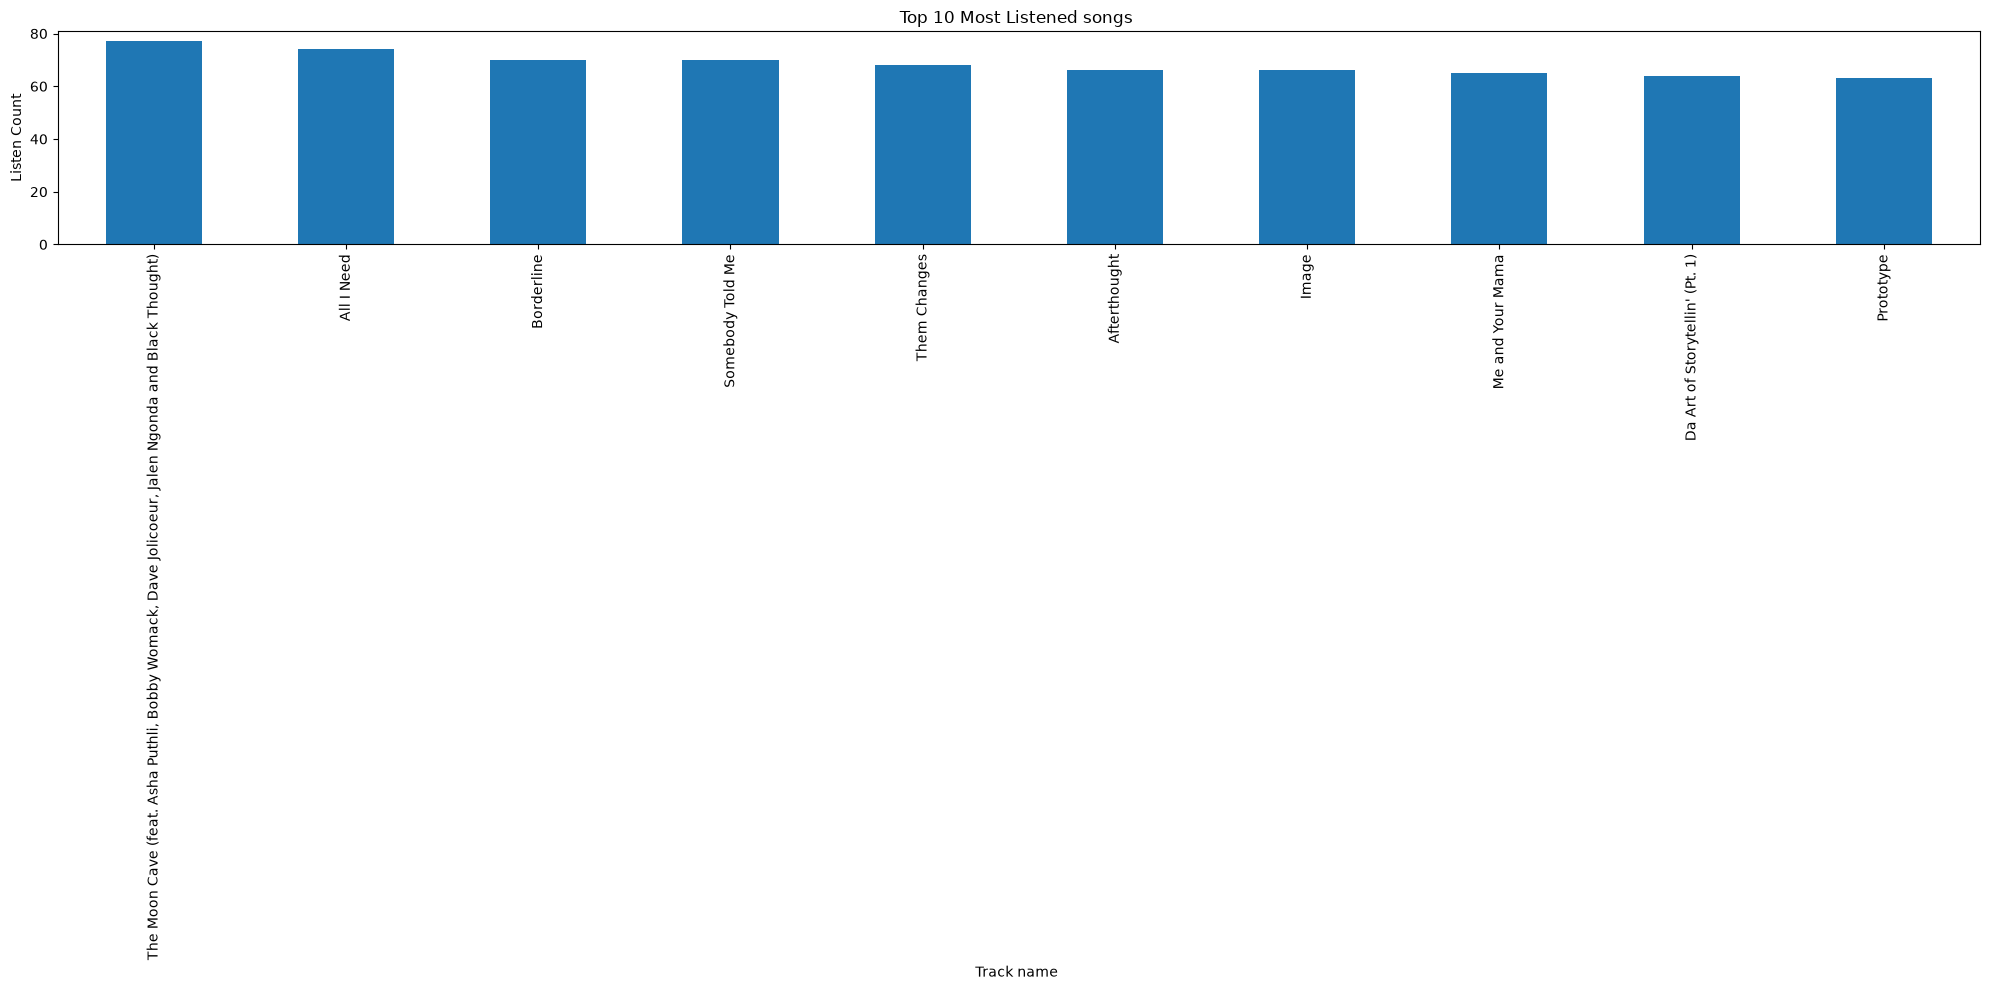

In [18]:
df_3['Track name'].value_counts().head(10).plot(
    kind='bar',
    figsize=(20, 10),
    title='Top 10 Most Listened songs ',
    xlabel='Track name ',
    ylabel='Listen Count',
    rot=90
)

plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

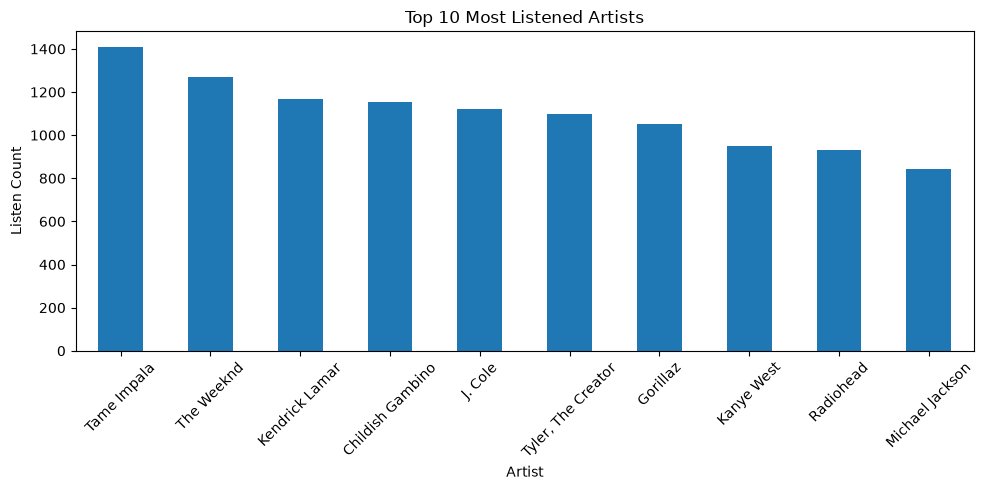

In [19]:
df_3['artist'].value_counts().head(10).plot(
    kind='bar',
    figsize=(10, 5),
    title='Top 10 Most Listened Artists',
    xlabel='Artist',
    ylabel='Listen Count',
    rot=45
)

plt.tight_layout()
plt.show

In [21]:
total_min = df_2["minutes"].sum()
print(f" You have listened for {total_min.round(0)} minutes  and {total_min/60} hrs")

 You have listened for 59480.0 minutes  and 991.3391119444444 hrs


In [22]:
total_min = df_2["minutes"].sum()
print(f" You have listened for {total_min} minutes  and {total_min/60} hrs")

 You have listened for 59480.34671666667 minutes  and 991.3391119444444 hrs


#### **Modelling**

In [30]:
df_4 = df_3.dropna(subset =["artist"] )
df_4["week"] = df["ts"].dt.tz_localize(None).dt.to_period("W").dt.start_time


In [31]:
weekly = df_4.groupby(["week", "artist"])["minutes"].sum().reset_index()


In [40]:
weekly = weekly[(weekly["week"] > weekly["week"].min()) & (weekly["week"] < weekly["week"].max())]
weekly


,week,artist,minutes
3412,2026-03-02,10cc,0.015217
3413,2026-03-02,112,4.830933
3414,2026-03-02,2Pac,0.041800
3415,2026-03-02,5 Seconds of Summer,0.028783
3416,2026-03-02,54 Ultra,0.250950
...,...,...,...
11001,2026-08-03,slowthai,0.000383
11002,2026-08-03,tg.blk,0.024883
11003,2026-08-03,visioner.,0.006383
11004,2026-08-03,¥$,3.850750


NameError: name 'weekly' is not defined